<a href="https://colab.research.google.com/github/AlbertP97/Med-VQA-Survey/blob/main/Kvasir_VQA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Kvasir Dataset Analysis

This notebook analyzes the Kvasir VQA dataset for the doctoral research project (Paper 2).

## Dataset Overview
Kvasir is a dataset of medical visual question answering focusing on gastrointestinal tract images.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import nltk
from nltk.tokenize import word_tokenize

# Download the required NLTK data
nltk.download('punkt', quiet=True)

# Visualization configuration
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 2. Data Loading

In [2]:
from google.colab import files
import pandas as pd
import io

# Select and upload the CSV file from the computer
uploaded_files = files.upload()

# Get the uploaded file name
file_name = next(iter(uploaded_files))

# Read the CSV file and convert it to a DataFrame
df = pd.read_csv(
    io.BytesIO(uploaded_files[file_name])
)


Saving Kvasir-VQA.csv to Kvasir-VQA.csv


In [3]:
import io

# Read the original DataFrame again to ensure that the 'complexity' values are numeric before mapping
df = pd.read_csv(io.BytesIO(uploaded_files[file_name]))

# Normalize answers to lowercase to avoid duplicates caused by capitalization
df['answer'] = df['answer'].astype(str).str.strip().str.lower()

# Normalize questions
df['question'] = df['question'].astype(str).str.strip()

# Map complexity values to the desired levels
complexity_map = {1: 'Level 1', 2: 'Level 2', 3: 'Level 3'}
df['complexity'] = df['complexity'].map(complexity_map)

print(f"Dataset loaded and mapped successfully")
print(f"Number of rows: {len(df)}")
print(f"Number of columns: {len(df.columns)}")

Dataset loaded and mapped successfully
Number of rows: 159549
Number of columns: 6


In [4]:
# Define the list of allowed variables
variables = [
    'img_id',
    'complexity',
    'question',
    'answer',
    'original',
    'question_class'
]

print("Allowed variables in Kvasir:")
for var in variables:
    print(f"  - {var}")

Allowed variables in Kvasir:
  - img_id
  - complexity
  - question
  - answer
  - original
  - question_class


In [5]:
# Calculate question and answer length (in characters)
df['question_length'] = df['question'].str.len()
df['answer_length'] = df['answer'].str.len()

# Calculate length in words using NLTK without whitespace
def count_words_nltk(text: str) -> int:
    """
    Count the words in text using NLTK, excluding whitespace.

    Args:
        text: The text to analyze

    Returns:
        Number of words excluding whitespace
    """
    if not isinstance(text, str) or not text.strip():
        return 0
    tokens = word_tokenize(text.lower())
    # Filter tokens that contain only whitespace or are empty
    words = [token for token in tokens if token.strip()]
    return len(words)

# Download the required punkt_tab tokenizer
nltk.download('punkt_tab', quiet=True)
df['question_words'] = df['question'].apply(count_words_nltk)
df['answer_words'] = df['answer'].apply(count_words_nltk)

print("Length columns created successfully")
print(f"  - question_length (characters)")
print(f"  - answer_length (characters)")
print(f"  - question_words (words - NLTK without whitespace)")
print(f"  - answer_words (words - NLTK without whitespace)")

Length columns created successfully
  - question_length (characters)
  - answer_length (characters)
  - question_words (words - NLTK without whitespace)
  - answer_words (words - NLTK without whitespace)


Vocabulary Diversity Metrics (Normalized Match):
--------------------------------------------------
Total Questions: 159549
Unique Questions: 38405
Question Diversity (%): 24.07
Total Answers: 159549
Unique Answers: 79390
Answer Diversity (%): 49.76


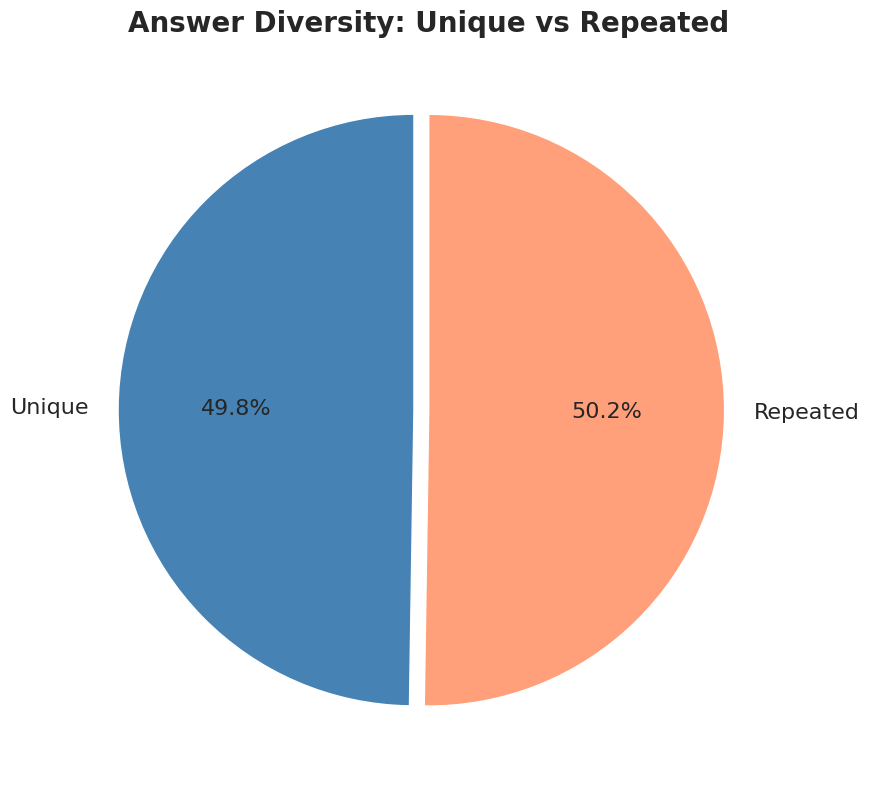

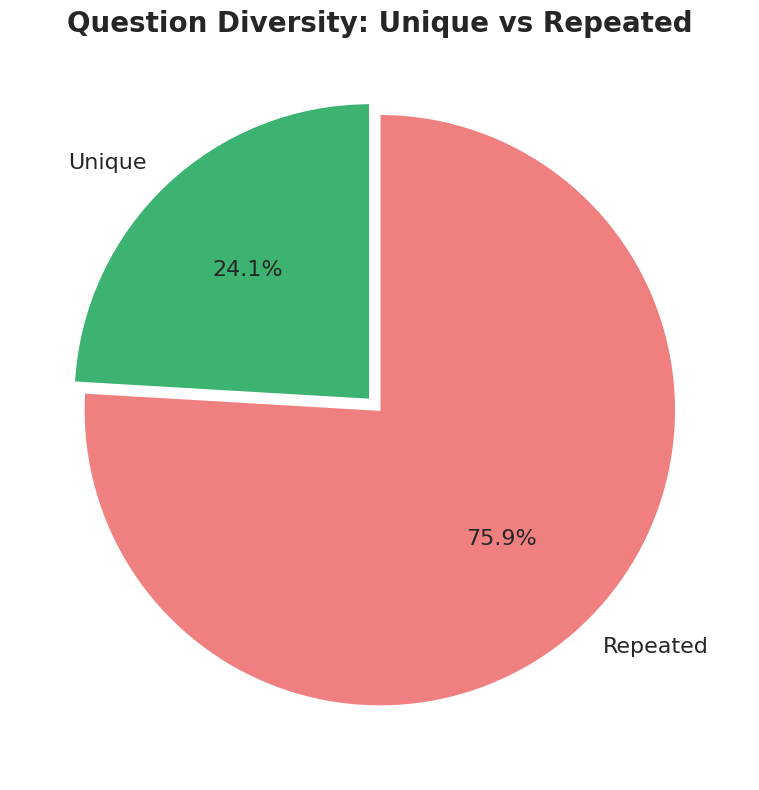

In [6]:
# Function to normalize text
def normalize_text(text: str) -> str:
    """
    Normalize text for comparison by converting it to lowercase and removing extra whitespace.

    Args:
        text: The text to normalize

    Returns:
        Normalized text
    """
    if not isinstance(text, str):
        return ""
    return ' '.join(text.lower().strip().split())

# Calculate diversity metrics
normalized_questions = df['question'].apply(normalize_text)
normalized_answers = df['answer'].apply(normalize_text)

total_questions = len(normalized_questions)
unique_questions = normalized_questions.nunique()
total_answers = len(normalized_answers)
unique_answers = normalized_answers.nunique()

diversity_metrics = {
    'Total Questions': total_questions,
    'Unique Questions': unique_questions,
    'Question Diversity (%)': (unique_questions / total_questions) * 100,
    'Total Answers': total_answers,
    'Unique Answers': unique_answers,
    'Answer Diversity (%)': (unique_answers / total_answers) * 100
}

print("Vocabulary Diversity Metrics (Normalized Match):")
print("-" * 50)
for metric, value in diversity_metrics.items():
    if isinstance(value, float):
        print(f"{metric}: {value:.2f}")
    else:
        print(f"{metric}: {value}")

# Answer diversity visualization
repeated_answers = total_answers - unique_answers
fig = plt.figure(figsize=(10, 8))
colors_a = ['steelblue', 'lightsalmon']
plt.pie([unique_answers, repeated_answers], labels=['Unique', 'Repeated'],
        autopct='%1.1f%%', colors=colors_a, startangle=90,
        explode=(0.05, 0), textprops={'fontsize': 16})
plt.title('Answer Diversity: Unique vs Repeated', fontsize=20, fontweight='bold')
plt.tight_layout()
plt.show();

# Question diversity visualization
repeated_questions = total_questions - unique_questions
fig = plt.figure(figsize=(10, 8))
colors_q = ['mediumseagreen', 'lightcoral']
plt.pie([unique_questions, repeated_questions], labels=['Unique', 'Repeated'],
        autopct='%1.1f%%', colors=colors_q, startangle=90,
        explode=(0.05, 0), textprops={'fontsize': 16})
plt.title('Question Diversity: Unique vs Repeated', fontsize=20, fontweight='bold')
plt.tight_layout()
plt.show();

## 3. Exploratory Data Analysis

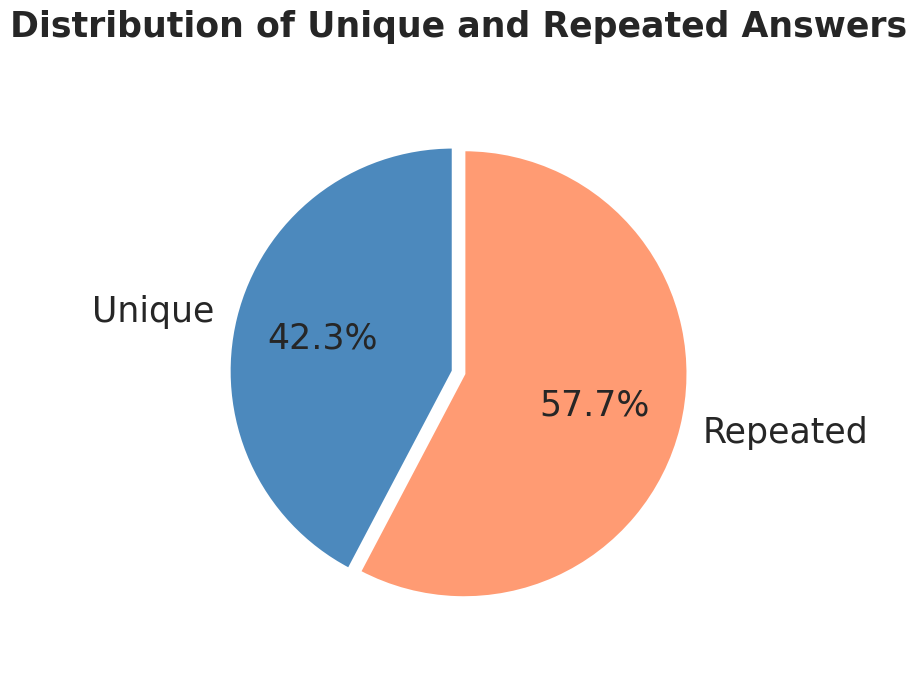

In [7]:
import matplotlib.pyplot as plt

# Frequency of each answer
answer_counts = df['answer'].dropna().value_counts()

unique_answers = answer_counts[answer_counts == 1].sum()
repeated_answers = answer_counts[answer_counts > 1].sum()

values = [unique_answers, repeated_answers]
labels = ['Unique', 'Repeated']
colors = ['#4C89BD', '#FF9B73']

fig, ax = plt.subplots(figsize=(8, 7))

ax.pie(
    values,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    explode=(0.025, 0.025),
    textprops={'fontsize': 25},
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 2
    }
)

ax.set_title(
    'Distribution of Unique and Repeated Answers',
    fontsize=25,
    fontweight='bold',
    pad=20
)

ax.axis('equal')
plt.tight_layout()
plt.show()


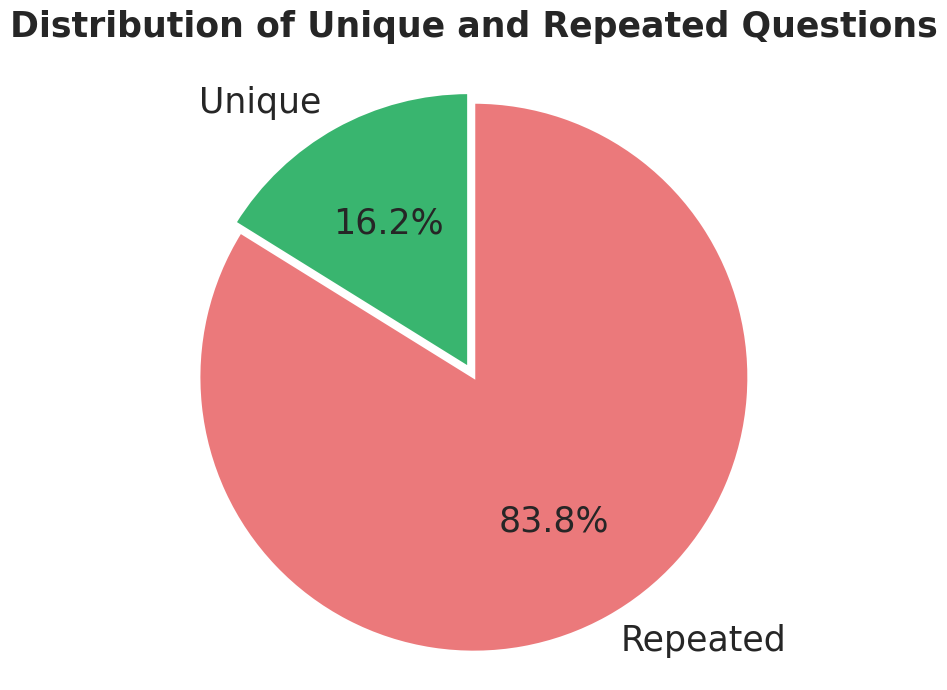

In [8]:

import matplotlib.pyplot as plt

# Frequency of each question
question_counts = df['question'].dropna().value_counts()

unique_questions = question_counts[question_counts == 1].sum()
repeated_questions = question_counts[question_counts > 1].sum()

values = [unique_questions, repeated_questions]
labels = ['Unique', 'Repeated']
colors = ['#39B56F', '#EB797B']

fig, ax = plt.subplots(figsize=(8, 7))

ax.pie(
    values,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    explode=(0.04, 0),
    textprops={'fontsize': 25},
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 2
    }
)

ax.set_title(
    'Distribution of Unique and Repeated Questions',
    fontsize=25,
    fontweight='bold',
    pad=20
)

ax.axis('equal')
plt.tight_layout()
plt.show()


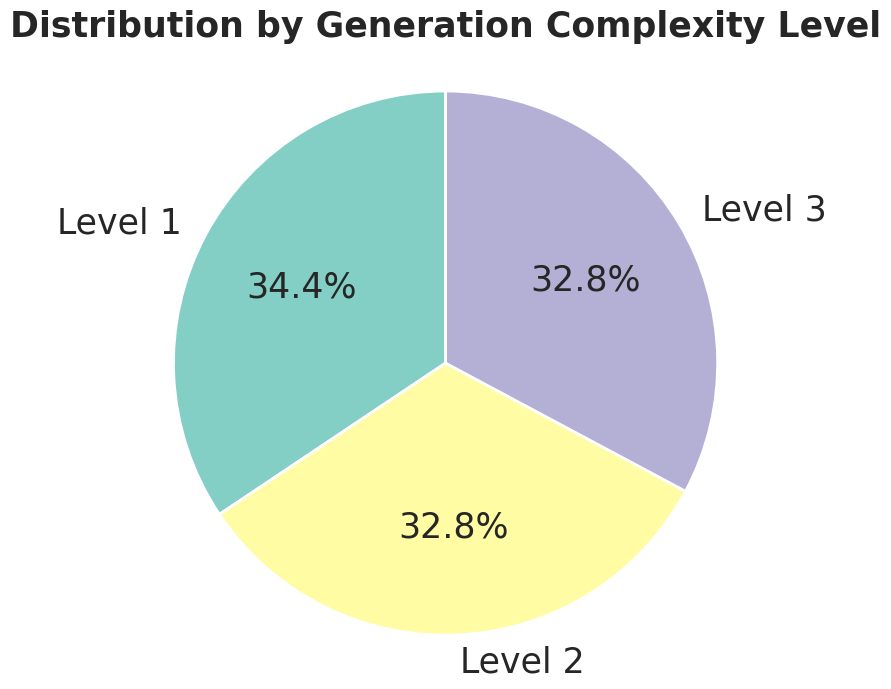

In [9]:
import matplotlib.pyplot as plt

# The correct order for the newly mapped labels
complexity_order = ['Level 1', 'Level 2', 'Level 3']

complexity_counts = (
    df['complexity']
    .value_counts()
    .reindex(complexity_order, fill_value=0)
)

colors = ['#83CEC5', '#FFFCA3', '#B3AFD5']

fig, ax = plt.subplots(figsize=(8, 7))

ax.pie(
    complexity_counts.values,
    labels=complexity_counts.index,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 25},
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 2
    }
)

ax.set_title(
    'Distribution by Generation Complexity Level',
    fontsize=25,
    fontweight='bold',
    pad=20
)

ax.axis('equal')
plt.tight_layout()
plt.show()

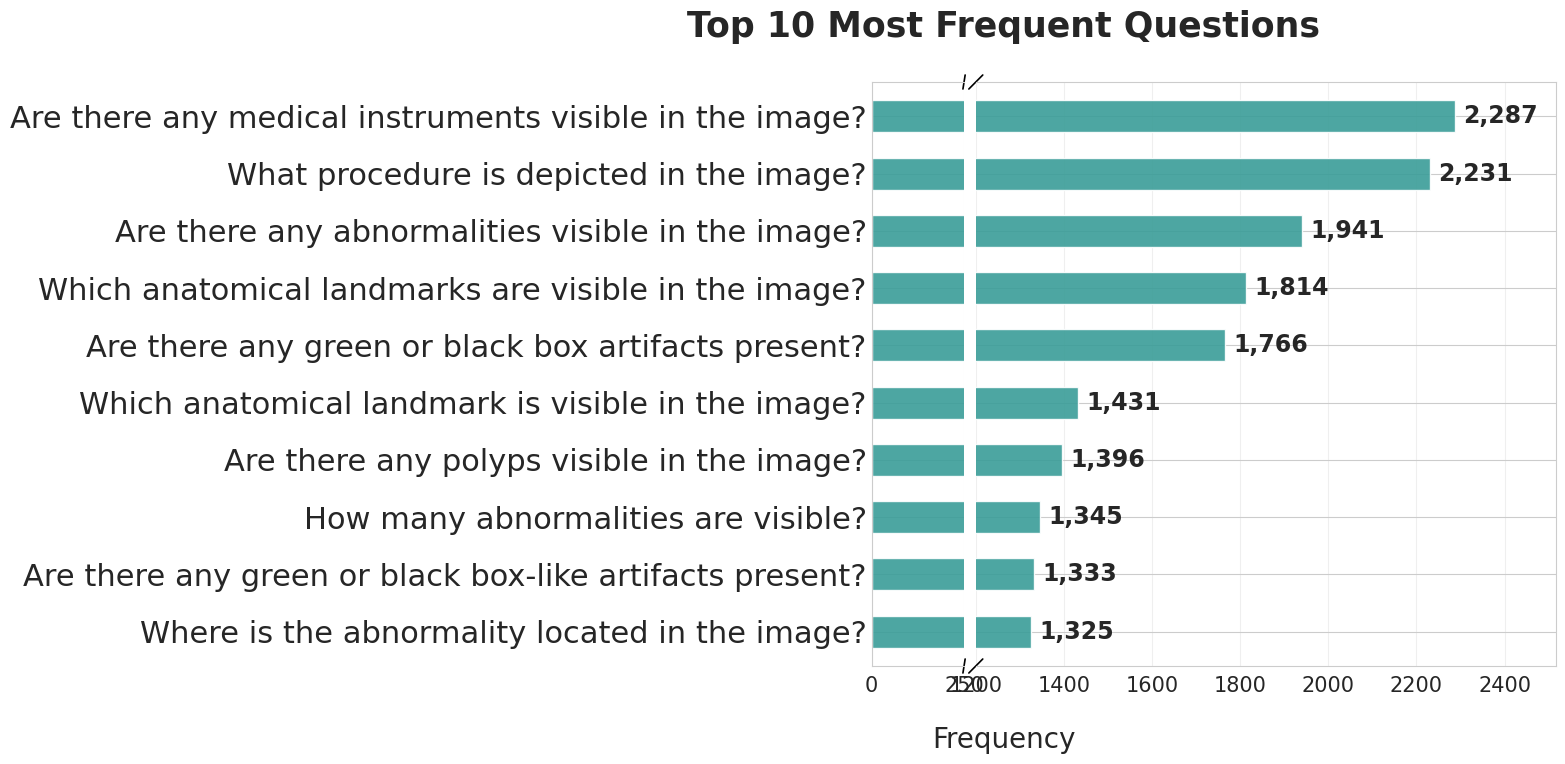

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# TOP 10 MOST FREQUENT QUESTIONS - BROKEN X-AXIS
# ============================================================

top_questions = (
    df['question']
    .dropna()
    .astype(str)
    .str.strip()
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

# Shorten only excessively long labels
labels = [
    question if len(question) <= 85
    else question[:82] + '...'
    for question in top_questions.index
]

values = top_questions.values
positions = np.arange(len(top_questions)) * 0.50
maximum = values.max()

# Break limits
left_limit = 250
right_limit = 1200

# Create two panels that share the Y-axis
fig, (ax_left, ax_right) = plt.subplots(
    1, 2,
    sharey=True,
    figsize=(12, 8),
    gridspec_kw={
        'width_ratios': [0.55, 3.45],
        'wspace': 0.035
    }
)

# Draw the same bars in both panels
for ax in (ax_left, ax_right):
    ax.barh(
        positions,
        values,
        height=0.28,
        color='#3A9D98',
        alpha=0.90
    )

    ax.set_axisbelow(True)
    ax.grid(axis='x', alpha=0.30)
    ax.tick_params(axis='x', labelsize=15)
    ax.tick_params(axis='y', length=0)

# Show only the required segments
ax_left.set_xlim(0, left_limit)
ax_right.set_xlim(right_limit, maximum * 1.10)

# Question labels
ax_left.set_yticks(positions)
ax_left.set_yticklabels(
    labels,
    fontsize=22
)

# Do not repeat labels in the right panel
ax_right.tick_params(
    axis='y',
    left=False,
    labelleft=False
)

# Hide interior borders
ax_left.spines['right'].set_visible(False)
ax_right.spines['left'].set_visible(False)

# Diagonal break marks
mark = 0.012
style = dict(
    color='black',
    linewidth=1.2,
    clip_on=False
)

for y in (0, 1):
    ax_left.plot(
        (1 - mark, 1 + mark),
        (y - mark, y + mark),
        transform=ax_left.transAxes,
        **style
    )

    ax_right.plot(
        (-mark, mark),
        (y - mark, y + mark),
        transform=ax_right.transAxes,
        **style
    )

# Show frequencies at the ends of the bars
offset = (maximum - right_limit) * 0.015

for position, value in zip(positions, values):
    ax_right.annotate(
        f'{value:,}',
        xy=(value, position),
        xytext=(6, 0),
        textcoords='offset points',
        va='center',
        ha='left',
        fontsize=17,
        fontweight='bold'
    )

# Matching vertical limits
ax_left.set_ylim(
    positions[0] - 0.30,
    positions[-1] + 0.30
)

fig.suptitle(
    'Top 10 Most Frequent Questions',
    fontsize=25,
    fontweight='bold',
    y=0.97
)

fig.supxlabel(
    'Frequency',
    fontsize=20,
    y=0.04
)

plt.subplots_adjust(
    left=0.39,
    right=0.96,
    top=0.88,
    bottom=0.15
)

plt.show()

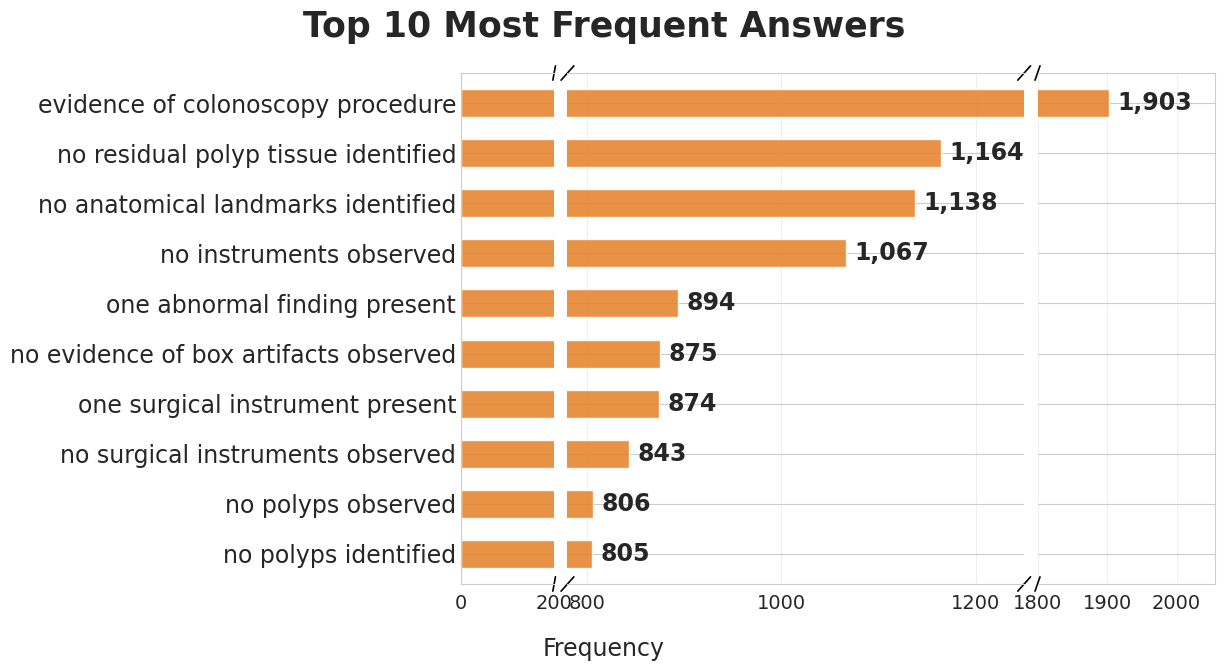

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# TOP 10 MOST FREQUENT ANSWERS - TWO X-AXIS BREAKS
# ============================================================

top_answers = (
    df['answer']
    .dropna()
    .astype(str)
    .str.strip()
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

# Shorten excessively long answers
labels = [
    answer if len(answer) <= 55
    else answer[:52] + '...'
    for answer in top_answers.index
]

values = top_answers.values
positions = np.arange(len(top_answers)) * 0.50
maximum = values.max()

# Ranges to display
first_end = 200
second_start = 780
second_end = 1250
third_start = 1800

# Create three panels
fig, (ax_first, ax_second, ax_third) = plt.subplots(
    1, 3,
    sharey=True,
    figsize=(13, 7),
    gridspec_kw={
        'width_ratios': [0.55, 2.7, 1.05],
        'wspace': 0.055
    }
)

axes = (ax_first, ax_second, ax_third)

# Draw the bars in all three panels
for ax in axes:
    ax.barh(
        positions,
        values,
        height=0.28,
        color='#E68632',
        alpha=0.90
    )

    ax.set_axisbelow(True)
    ax.grid(axis='x', alpha=0.30)
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', length=0)

# Limits of each segment
ax_first.set_xlim(0, first_end)
ax_second.set_xlim(second_start, second_end)
ax_third.set_xlim(third_start, maximum * 1.08)

# Specific ticks to avoid overlapping numbers
ax_first.set_xticks([0, 200])
ax_second.set_xticks([800, 1000, 1200])
ax_third.set_xticks([1800, 1900, 2000])

# Answer labels
ax_first.set_yticks(positions)
ax_first.set_yticklabels(
    labels,
    fontsize=17
)

# Do not repeat labels in the remaining panels
for ax in (ax_second, ax_third):
    ax.tick_params(
        axis='y',
        left=False,
        labelleft=False
    )

# Hide borders where breaks occur
ax_first.spines['right'].set_visible(False)

ax_second.spines['left'].set_visible(False)
ax_second.spines['right'].set_visible(False)

ax_third.spines['left'].set_visible(False)

# Diagonal marks for both breaks
mark = 0.014
style = dict(
    color='black',
    linewidth=1.2,
    clip_on=False
)

for y in (0, 1):

    # First break: between the first and second panels
    ax_first.plot(
        (1 - mark, 1 + mark),
        (y - mark, y + mark),
        transform=ax_first.transAxes,
        **style
    )

    ax_second.plot(
        (-mark, mark),
        (y - mark, y + mark),
        transform=ax_second.transAxes,
        **style
    )

    # Second break: between the second and third panels
    ax_second.plot(
        (1 - mark, 1 + mark),
        (y - mark, y + mark),
        transform=ax_second.transAxes,
        **style
    )

    ax_third.plot(
        (-mark, mark),
        (y - mark, y + mark),
        transform=ax_third.transAxes,
        **style
    )

# Place frequencies in the corresponding panel
for position, value in zip(positions, values):

    if value >= third_start:
        selected_ax = ax_third
    elif value >= second_start:
        selected_ax = ax_second
    else:
        selected_ax = ax_first

    selected_ax.annotate(
        f'{value:,}',
        xy=(value, position),
        xytext=(6, 0),
        textcoords='offset points',
        va='center',
        ha='left',
        fontsize=17,
        fontweight='bold'
    )

# Vertical limits
ax_first.set_ylim(
    positions[0] - 0.30,
    positions[-1] + 0.30
)

# Title and overall label
fig.suptitle(
    'Top 10 Most Frequent Answers',
    fontsize=25,
    fontweight='bold',
    y=0.97
)

fig.supxlabel(
    'Frequency',
    fontsize=17,
    y=0.04
)

plt.subplots_adjust(
    left=0.39,
    right=0.97,
    top=0.88,
    bottom=0.15
)

plt.show()

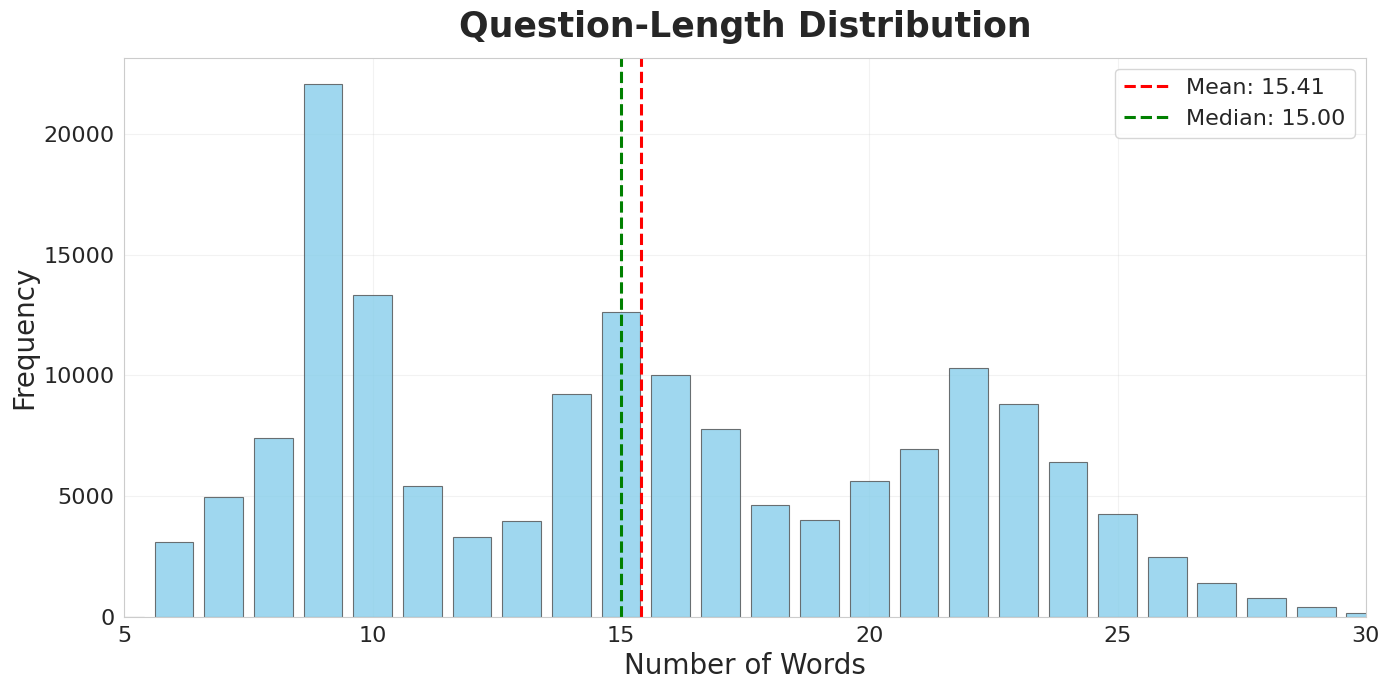

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Ensure that the column exists in the DataFrame in case the dataset was reloaded
if 'question_words' not in df.columns:
    if 'count_words_nltk' in globals():
        df['question_words'] = df['question'].apply(count_words_nltk)
    else:
        # Quick fallback in case the function is not defined in the kernel
        df['question_words'] = df['question'].astype(str).apply(lambda x: len(x.split()))

question_words = df['question_words'].dropna()

# Keep only questions containing 5 to 30 words
question_words_plot = question_words[
    question_words.between(5, 30)
]

# Statistics calculated using all data
mean_question = question_words.mean()
median_question = question_words.median()

# One bar for each integer from 5 to 30
bins_question = np.arange(4.5, 31.5, 1)

fig, ax = plt.subplots(figsize=(14, 7))

ax.hist(
    question_words_plot,
    bins=bins_question,
    rwidth=0.78,
    color='skyblue',
    edgecolor='#4F4F4F',
    linewidth=0.8,
    alpha=0.80
)

ax.axvline(
    mean_question,
    color='red',
    linestyle='--',
    linewidth=2.2,
    label=f'Mean: {mean_question:.2f}'
)

ax.axvline(
    median_question,
    color='green',
    linestyle='--',
    linewidth=2.2,
    label=f'Median: {median_question:.2f}'
)

ax.set_xlim(5, 30)
ax.set_xticks(np.arange(5, 31, 5))

ax.set_xlabel('Number of Words', fontsize=20)
ax.set_ylabel('Frequency', fontsize=20)

ax.set_title(
    'Question-Length Distribution',
    fontsize=25,
    fontweight='bold',
    pad=15
)

ax.tick_params(axis='both', labelsize=16)
ax.legend(fontsize=16)
ax.set_axisbelow(True)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

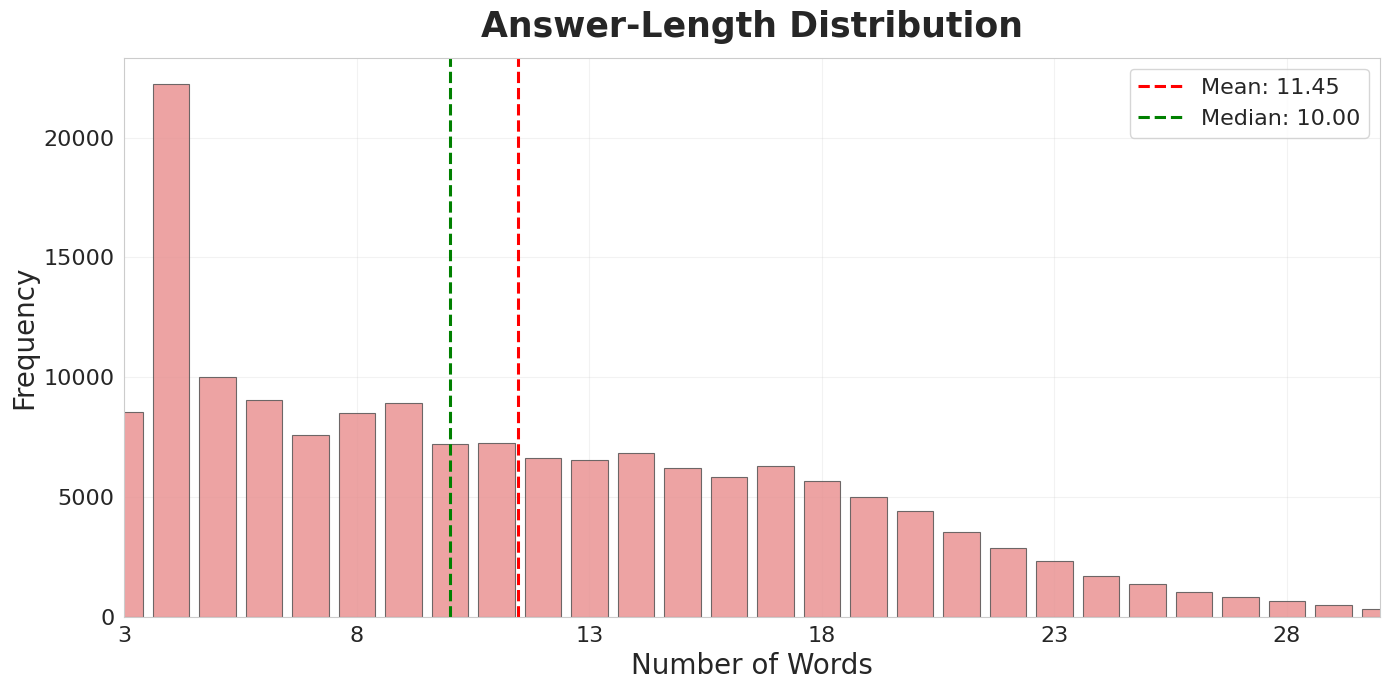

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Ensure that the column exists in the DataFrame in case the dataset was reloaded
if 'answer_words' not in df.columns:
    if 'count_words_nltk' in globals():
        df['answer_words'] = df['answer'].apply(count_words_nltk)
    else:
        # Quick fallback in case the function is not defined in the kernel
        df['answer_words'] = df['answer'].astype(str).apply(lambda x: len(x.split()))

answer_words = df['answer_words'].dropna()

# Keep only answers containing 3 to 30 words
answer_words_plot = answer_words[
    answer_words.between(3, 30)
]

# Statistics calculated using all data
mean_answer = answer_words.mean()
median_answer = answer_words.median()

# One bar for each integer from 3 to 30
bins_answer = np.arange(2.5, 31.5, 1)

fig, ax = plt.subplots(figsize=(14, 7))

ax.hist(
    answer_words_plot,
    bins=bins_answer,
    rwidth=0.78,
    color='#E98F8F',
    edgecolor='#4F4F4F',
    linewidth=0.8,
    alpha=0.82
)

ax.axvline(
    mean_answer,
    color='red',
    linestyle='--',
    linewidth=2.2,
    label=f'Mean: {mean_answer:.2f}'
)

ax.axvline(
    median_answer,
    color='green',
    linestyle='--',
    linewidth=2.2,
    label=f'Median: {median_answer:.2f}'
)

ax.set_xlim(3, 30)
ax.set_xticks(np.arange(3, 31, 5))

ax.set_xlabel('Number of Words', fontsize=20)
ax.set_ylabel('Frequency', fontsize=20)

ax.set_title(
    'Answer-Length Distribution',
    fontsize=25,
    fontweight='bold',
    pad=15
)

ax.tick_params(axis='both', labelsize=16)
ax.legend(fontsize=16)
ax.set_axisbelow(True)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()